In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram

In [2]:
transactions = [
["Bread", "Butter", "Milk"],
["Bread", "Butter", "Eggs"],
["Milk", "Cereal"],
["Bread", "Eggs"],
["Milk", "Cereal", "Yogurt"],
["Diapers", "Beer"],
["Diapers", "Beer", "Chips"],
["Apples", "Bananas"],
["Apples", "Bananas", "Milk"],
["Bread", "Butter", "Milk", "Eggs"],
["Cereal", "Milk"],
["Bread", "Butter", "Milk", "Eggs"],
["Apples", "Milk"],
["Diapers", "Beer", "Bread", "Eggs"],
["Yogurt", "Cereal"],
["Bread", "Butter", "Bananas", "Milk"],
["Milk", "Eggs"],
["Apples", "Bananas", "Yogurt"],
["Bread", "Butter", "Cereal", "Milk"],
["Chips", "Salsa"]
]

In [3]:
def support(candidate_itemset, list_of_transactions):
    candidate = set(candidate_itemset)
    n = 0
    for transaction in list_of_transactions:
        if candidate.issubset(transaction):
            n += 1
    return n/len(list_of_transactions)

In [4]:
def confidence(X, y, list_of_transactions):
    num = support(X|y, list_of_transactions)
    den = support(X, list_of_transactions)
    if den == 0:
        raise ValueError('Cannot divide by 0')
    return num/den

In [5]:
def join(freq):
    prev = sorted(freq)
    candidates = []
    for i in range(len(prev)):
        for j in range(i+1, len(prev)):
            t1, t2 = prev[i], prev[j]
            if t1[:-1] == t2[:-1]:
                candidates.append(t1 + (t2[-1],))
    return candidates

In [6]:
def prune(candidates, freq):
    freq = set(freq)
    kept, pruned = [], []
    for c in candidates:
        all_freq = True
        for idx in range(len(c)):
            subset = c[:idx] + c[idx+1:]
            if subset not in freq:
                all_freq = False
                break
        if all_freq:
            kept.append(c)
        else:
            pruned.append(c)
    return kept, pruned

In [7]:
def count(candidates, list_of_transactions, min_sup):
    frequent = {}
    for c in candidates:
        s = support(c, list_of_transactions)
        if s >= min_sup:
            frequent[c] = s
    return frequent


In [8]:
def frequent_1_itemsets(list_of_transactions, min_sup):
    items = {item for t in list_of_transactions for item in t}
    candidates = [(item,) for item in sorted(items)]
    return count(candidates, list_of_transactions, min_sup)

In [9]:
def apriori(list_of_transactions, min_sup):
    levels = {}
    pruned_log = {}
    candidates_log = {}
    levels[1] = frequent_1_itemsets(list_of_transactions, min_sup)
    k = 2
    while levels[k-1]:
        candidates = join(list(levels[k-1]))
        kept, pruned = prune(candidates, list(levels[k-1]))
        pruned_log[k] = pruned
        levels[k] = count(kept, list_of_transactions, min_sup)
        candidates_log[k] = len(candidates)
        k += 1
    return levels, pruned_log, candidates_log    

In [10]:
levels, pruned_log, candidates_log = apriori(transactions, 0.25)

for k, itemsets in levels.items():
    if not itemsets:
        continue
    print(f"k = {k}: {len(itemsets)} frequent itemsets")
    for itemset, s in sorted(itemsets.items()):
        print(f"{set(itemset)}   support = {s:.2f}")
for k in pruned_log:
    print(f"k = {k}: {candidates_log[k]} candidates generated, "
          f"{len(pruned_log[k])} pruned -> {pruned_log[k]}")

k = 1: 5 frequent itemsets
{'Bread'}   support = 0.40
{'Butter'}   support = 0.30
{'Cereal'}   support = 0.25
{'Eggs'}   support = 0.30
{'Milk'}   support = 0.55
k = 2: 4 frequent itemsets
{'Butter', 'Bread'}   support = 0.30
{'Eggs', 'Bread'}   support = 0.25
{'Milk', 'Bread'}   support = 0.25
{'Milk', 'Butter'}   support = 0.25
k = 3: 1 frequent itemsets
{'Milk', 'Butter', 'Bread'}   support = 0.25
k = 2: 10 candidates generated, 0 pruned -> []
k = 3: 3 candidates generated, 2 pruned -> [('Bread', 'Butter', 'Eggs'), ('Bread', 'Eggs', 'Milk')]
k = 4: 0 candidates generated, 0 pruned -> []


In [11]:
F_sup = {}
for k in levels:
    F_sup.update(levels[k])
def rule_confidence(F, H, F_sup):
    X = tuple(item for item in F if item not in H)
    return F_sup[F]/F_sup[X]

In [12]:
def count_rules(F, H, F_sup, min_conf):
    passed = {}
    for h in H:
        c = rule_confidence(F, h, F_sup)
        if c >= min_conf:
            passed[h] = c
    return passed

In [13]:
def apriori_rules(F, F_sup, min_conf):
    rules = {}
    H = count_rules(F, [(item,) for item in F], F_sup, min_conf)
    rules.update(H)
    m = 2
    while H and m < len(F):
        candidates = join(list(H))
        kept, pruned = prune(candidates, H)
        H = count_rules(F, kept, F_sup, min_conf)
        rules.update(H)
        m += 1
    return rules

In [14]:
all_rules = []
for F in F_sup:
    if len(F) < 2:
        continue
    rules = apriori_rules(F, F_sup, 0.6)
    for h, c in rules.items():
        X = tuple(item for item in F if item not in h)  
        lift = c/F_sup[h]                                  
        all_rules.append((X, h, F_sup[F], c, lift))
rules_df = pd.DataFrame([{
            'Rule': f"{set(X)} -> {set(h)}",
            'Support': s,
            'Confidence': c,
            'Lift': l
        }for X, h, s, c, l in all_rules]).round(3)
rules_df

,Rule,Support,Confidence,Lift
0,{'Butter'} -> {'Bread'},0.30,1.000,2.500
1,{'Bread'} -> {'Butter'},0.30,0.750,2.500
2,{'Eggs'} -> {'Bread'},0.25,0.833,2.083
3,{'Bread'} -> {'Eggs'},0.25,0.625,2.083
4,{'Bread'} -> {'Milk'},0.25,0.625,1.136
5,{'Butter'} -> {'Milk'},0.25,0.833,1.515
6,"{'Milk', 'Butter'} -> {'Bread'}",0.25,1.000,2.500
7,"{'Milk', 'Bread'} -> {'Butter'}",0.25,1.000,3.333
8,"{'Butter', 'Bread'} -> {'Milk'}",0.25,0.833,1.515
9,"{'Butter'} -> {'Milk', 'Bread'}",0.25,0.833,3.333


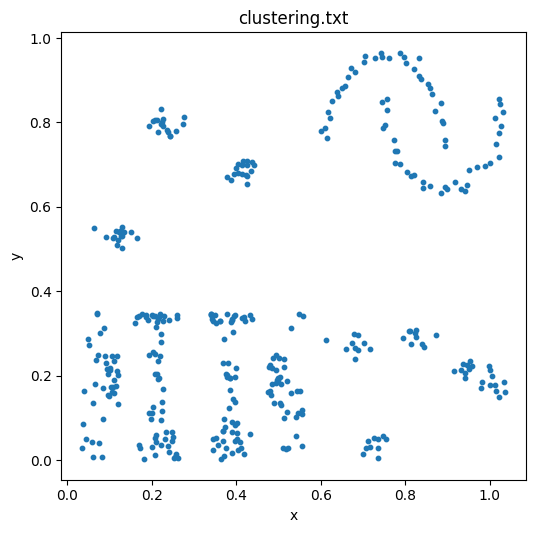

In [15]:
X = np.loadtxt("clustering.txt", delimiter=",")
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=10)
plt.gca().set_aspect("equal")
plt.title("clustering.txt")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## 13 clusters spotted visually

In [16]:
def distance_matrix(X):
    n = len(X)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):       
            d = np.sqrt(np.sum((X[i]-X[j])**2))
            D[i, j] = d
            D[j, i] = d            
    return D

In [17]:
def min_dist(row_i, row_j):
    return np.minimum(row_i, row_j)

In [18]:
def max_dist(row_i, row_j):
    return np.maximum(row_i, row_j)

In [19]:
def hac(D, cluster_dist):
    n = len(D)
    D = D.copy()                      
    np.fill_diagonal(D, np.inf)       
    cluster_id = list(range(n))       
    size = [1] * n                    
    merges = []
    for step in range(n - 1):
        i, j = np.unravel_index(np.argmin(D), D.shape)
        i, j = min(i, j), max(i, j)
        dist = D[i, j]
        merges.append([cluster_id[i], cluster_id[j], dist, size[i] + size[j]])
        new_row = cluster_dist(D[i], D[j])
        D[i, :] = new_row
        D[:, i] = new_row
        D[i, i] = np.inf            
        D[j, :] = np.inf
        D[:, j] = np.inf
        cluster_id[i] = n + step
        size[i] += size[j]
    return np.array(merges)

In [20]:
def plot_dendrogram(Z, k, title):
    plt.figure(figsize=(12, 5))
    dendrogram(Z, no_labels=True)
    cut = (Z[-k, 2] + Z[-(k - 1), 2]) / 2
    plt.axhline(cut, color="red", linestyle="--", label=f"cut for {k} clusters")
    plt.title(title)
    plt.ylabel("merge distance")
    plt.legend()
    plt.show()

In [21]:
def cluster_labels(Z, k):
    n = len(Z) + 1                          
    members = {i: [i] for i in range(n)}    
    for step in range(n-k):              
        a, b = int(Z[step, 0]), int(Z[step, 1])
        members[n + step] = members.pop(a) + members.pop(b)      
    labels = np.empty(n, dtype=int)
    for label, points in enumerate(members.values()):
        labels[points] = label              
    return labels

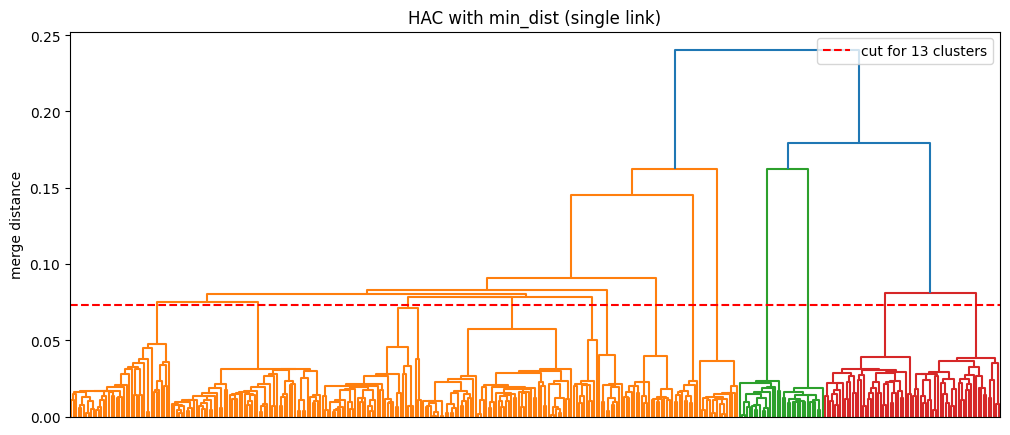

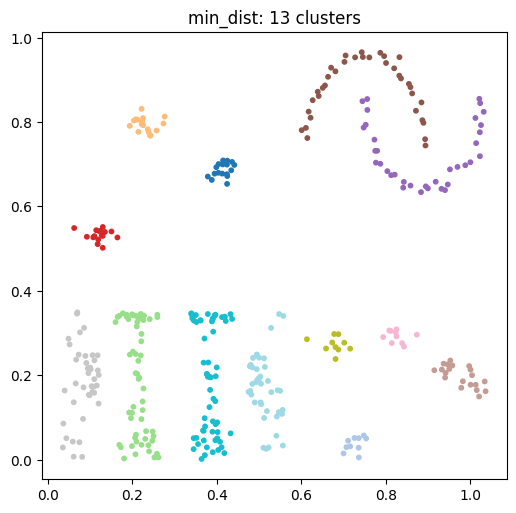

In [22]:
D = distance_matrix(X)
Z_min = hac(D, min_dist)
plot_dendrogram(Z_min, 13, "HAC with min_dist (single link)")
labels_min = cluster_labels(Z_min, 13)
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels_min, cmap="tab20", s=10)
plt.gca().set_aspect("equal")
plt.title("min_dist: 13 clusters")
plt.show()

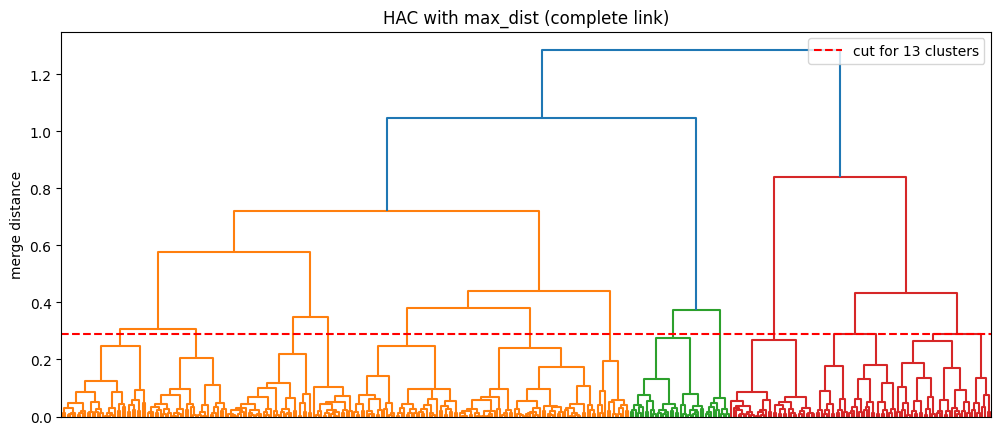

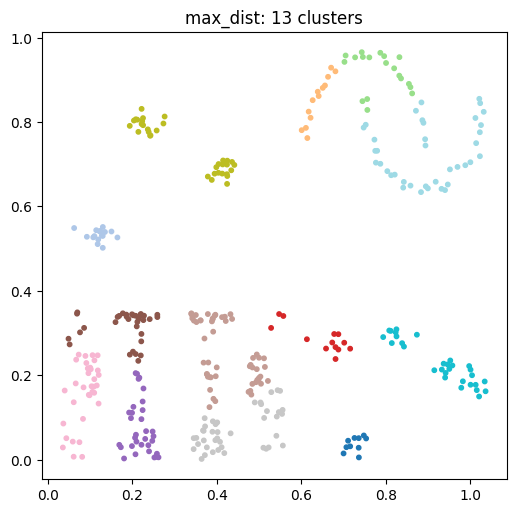

In [23]:
Z_max = hac(D, max_dist)
plot_dendrogram(Z_max, 13, "HAC with max_dist (complete link)")

labels_max = cluster_labels(Z_max, 13)
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels_max, cmap="tab20", s=10)
plt.gca().set_aspect("equal")
plt.title("max_dist: 13 clusters")
plt.show()